# Tutorial: SVM con Python y scikit-learn by Paola Michelle Ambriz Soto


## 1. Fundamentos teóricos

**¿Qué es una SVM?** Es un algoritmo que busca una línea para separar dos grupos. Intenta que exista el mayor espacio posible (margen) entre la línea y los puntos más cercanos de cada grupo.

**Vectores de soporte:** son los puntos de entrenamiento que más influyen en dónde se coloca la línea; están sobre el margen o dentro de él.

**Margen duro:** no permite violaciones del margen. **Margen blando:** permite algunas violaciones; el número **C** controla qué tanto se penalizan. Aquí usamos una SVM lineal con margen blando, aunque nuestros datos se diseñaron para ser separables.

**Ejemplo cotidiano:** si los puntos verdes y rojos están a lados opuestos de una calle, la SVM busca una calle recta lo más ancha posible entre ellos.

## 2. Matemáticas de la SVM lineal

Con dos variables, la decisión se calcula con una **suma de multiplicaciones**:

$$f(x)=w_1x_1+w_2x_2+b$$

- $x_1,x_2$: valores de un punto nuevo.
- $w_1,w_2$: números que aprende la SVM.
- $b$: número que mueve la recta.
- Si $f(x)>0$, predice **clase 1**; si $f(x)<0$, predice **clase 0**.
- La **recta separadora** es $w_1x_1+w_2x_2+b=0$.

**Ejemplo inventado**: si $w_1=2$, $w_2=1$, $b=-1$ y el punto es $(1,2)$, entonces $f(x)=2(1)+1(2)-1=3>0$, por lo que se asigna a la clase 1.

**Margen:** las dos rectas paralelas que delimitan el margen son $f(x)=+1$ y $f(x)=-1$. El ancho del margen es $2/\sqrt{w_1^2+w_2^2}$.

**Qué optimiza (solo interpretación):**

$$\min_{w,b,\xi}\frac{1}{2}\|w\|^2+C\sum_i\xi_i$$

El primer término busca un margen amplio; el segundo penaliza puntos que no cumplen el margen. No resolveremos esta minimización a mano: `SVC` encuentra los coeficientes.

## 2.1 Los kernels: **teoría solamente**

Cuando las clases se mezclan de manera curva, una recta puede no funcionar. Los **kernels** permiten a una SVM construir separaciones más flexibles.

| Tipo | Idea | Fórmula |
|---|---|---|
| Lineal | Comparar con un producto | $K(x,z)=x\cdot z$ |
| Polinomial | Permite fronteras más complejas | $K(x,z)=(\gamma\,x\cdot z+r)^d$ |
| RBF | Da más similitud a puntos cercanos | $K(x,z)=e^{-\gamma\|x-z\|^2}$ |

La formulación general que utiliza vectores de soporte es:

$$f(x)=\sum_{i\in SV}\alpha_i t_i K(x_i,x)+b$$

Aquí $\alpha_i$ es el peso del vector de soporte, $t_i$ es su clase con signo ($-1$ o $+1$), y $K$ mide la similitud.

**Importante:** en este tutorial **no usamos la suma con kernel ni calculamos RBF**. Usamos la versión mucho más sencilla: $f(x)=w_1x_1+w_2x_2+b$. En `scikit-learn`, `SVC(kernel="linear")` indica de forma explícita que la frontera será una recta. No se usa `gamma`.

## 3. Flujo del experimento

1. Leer el CSV local de 400 puntos. 2. Ver sus columnas y graficar. 3. Separar 80 % para entrenar y 20 % para probar. 4. Estandarizar. 5. Entrenar la SVM **lineal**. 6. Mostrar la recta y los vectores de soporte. 7. Comparar el cálculo **manual lineal** con `decision_function`. 8. Evaluar y probar puntos nuevos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42

## 4. Leer el nuevo dataset

El archivo se carga desde mi repositorio de github

In [ ]:
RUTA_CSV = "https://raw.githubusercontent.com/Michelleas31/Hands-on-5/refs/heads/main/dataset_svm.csv"  # ruta al dataset
df = pd.read_csv(RUTA_CSV)
print("Dimensiones:", df.shape)
print("Primeras cinco filas:")
print(df.head())

Dimensiones: (400, 3)
Primeras cinco filas:
       x1      x2  clase
0  1.5551  2.1798      1
1  1.5541  1.5173      1
2 -1.8267 -1.6005      0
3  1.6599  0.7557      1
4 -1.4809 -2.0959      0


## 5. Explorar y visualizar los datos

`x1` y `x2` son las dos características. `clase` es lo que queremos predecir: 0 o 1. Los 400 registros se generaron para que una **recta** pueda separar bien los dos grupos. Los valores son ilustrativos, no datos de personas reales.


Datos faltantes:
x1       0
x2       0
clase    0
dtype: int64

Ejemplos por clase:
clase
0    200
1    200
Name: count, dtype: int64

Resumen numérico:
           x1      x2  clase
count  400.00  400.00  400.0
mean    -0.01   -0.02    0.5
std      1.72    1.45    0.5
min     -3.10   -2.97    0.0
25%     -1.56   -1.34    0.0
50%     -0.09   -0.13    0.5
75%      1.57    1.30    1.0
max      3.17    2.99    1.0


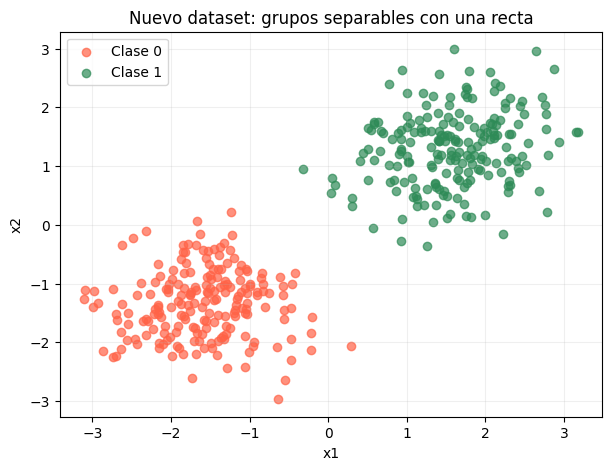

In [ ]:
print("\nDatos faltantes:")
print(df.isna().sum())
print("\nEjemplos por clase:")
print(df["clase"].value_counts().sort_index())
print("\nResumen numérico:")
print(df.describe().round(2))

plt.figure(figsize=(7, 5))
for clase, color in [(0, "tomato"), (1, "seagreen")]:
    puntos = df[df["clase"] == clase]
    plt.scatter(puntos["x1"], puntos["x2"], label=f"Clase {clase}", color=color, alpha=0.7)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Nuevo dataset: grupos separables con una recta")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

## 6. Dividir en entrenamiento y prueba

De 400 puntos: **320** se usan para entrenar y **80** para comprobar qué tan bien funciona el modelo. El grupo de prueba no se usa para aprender.

In [ ]:
X = df[["x1", "x2"]].values  # Entradas: dos columnas numéricas
y = df["clase"].values       # Respuestas correctas: 0 o 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))

Entrenamiento: 320 | Prueba: 80


## 7. Entrenar una SVM **solo lineal**

`StandardScaler` pone ambas variables en escalas comparables. La fórmula de estandarización es $z=(x-\text{promedio})/\text{desviación}$. Con `Pipeline`, el escalador aprende únicamente de entrenamiento.

`SVC(kernel="linear", C=1.0)` **obliga** al modelo a buscar una recta. Elegimos `C=1` para mantener el ejercicio sencillo. **No hacemos búsqueda de parámetros ni usamos RBF.**

In [ ]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))  # SOLO SVM LINEAL
])
modelo.fit(X_train, y_train)
print("Modelo entrenado:", modelo.named_steps["svm"])

Modelo entrenado: SVC(kernel='linear')


## 8. Ver los coeficientes de la recta y los vectores de soporte

Como el modelo usa datos estandarizados, `coef_` da primero los pesos para esos datos. Después los convertimos a las **unidades originales** de `x1` y `x2`, para poder escribir una fórmula sencilla directamente sobre el CSV.

In [ ]:
escalador = modelo.named_steps["escalador"]
svm = modelo.named_steps["svm"]

# Pesos y ajuste aprendidos en el espacio estandarizado:
w_escalado = svm.coef_[0]
b_escalado = svm.intercept_[0]

# Convertimos la recta a las unidades originales del CSV:
w = w_escalado / escalador.scale_
b = b_escalado - np.sum(w_escalado * escalador.mean_ / escalador.scale_)

print(f"Recta: f(x) = ({w[0]:.4f})*x1 + ({w[1]:.4f})*x2 + ({b:.4f})")
print("Vectores de soporte por clase:", svm.n_support_)
print("Total de vectores de soporte:", len(svm.support_vectors_))

# Los vectores guardados por SVC están estandarizados. Regresamos a unidades originales:
soportes_originales = escalador.inverse_transform(svm.support_vectors_)
print("Primeros 5 vectores de soporte (x1, x2):\n", soportes_originales[:5].round(3))

Recta: f(x) = (1.0106)*x1 + (0.9075)*x2 + (0.3924)
Vectores de soporte por clase: [4 3]
Total de vectores de soporte: 7
Primeros 5 vectores de soporte (x1, x2):
 [[-1.221 -0.174]
 [-0.466 -1.015]
 [-0.417 -0.825]
 [-1.24   0.213]
 [ 0.306  0.328]]


## 9. La fórmula hecha a mano vs. scikit-learn

Aquí está la respuesta más sencilla para explicar ante el profesor:

- **`f_manual`**: hacemos la cuenta $w_1x_1+w_2x_2+b$ usando los pesos aprendidos.
- **`f_sklearn`**: scikit-learn calcula el mismo puntaje usando `decision_function`.
- Los dos resultados deben coincidir (salvo pequeñas diferencias de computadora). **Aquí no interviene ningún kernel no lineal.**

In [ ]:
# Calculamos la fórmula lineal manual sobre los datos de prueba, sin kernel RBF:
f_manual = X_test @ w + b  # Equivale a w1*x1 + w2*x2 + b

# Pedimos el mismo puntaje a scikit-learn:
f_sklearn = modelo.decision_function(X_test)

print("Primeros 5 puntajes (manual):      ", f_manual[:5].round(4))
print("Primeros 5 puntajes (scikit-learn):", f_sklearn[:5].round(4))
print("¿Coinciden los dos procedimientos?", np.allclose(f_manual, f_sklearn))

Primeros 5 puntajes (manual):       [-3.0561  3.3165  4.2165 -2.504  -1.4691]
Primeros 5 puntajes (scikit-learn): [-3.0561  3.3165  4.2165 -2.504  -1.4691]
¿Coinciden los dos procedimientos? True


## 10. Dibujar la recta, sus márgenes y los vectores de soporte

La frontera es $f(x)=0$. Las dos rectas discontinuas indican $f(x)=+1$ y $f(x)=-1$. Los círculos negros identifican los vectores de soporte.

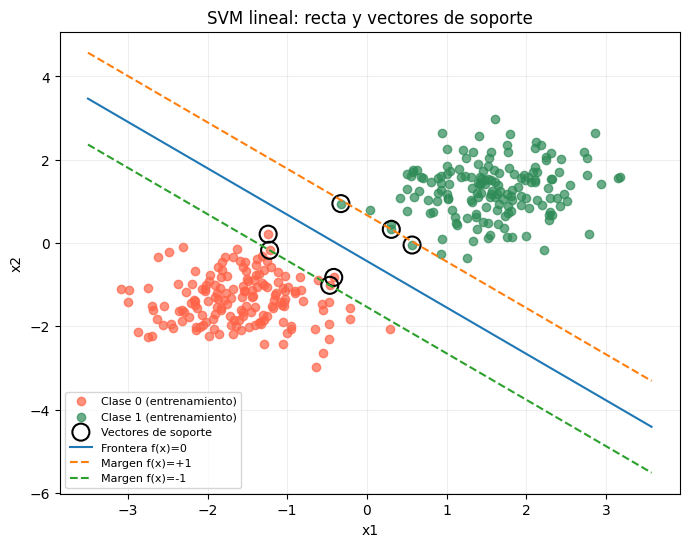

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
for clase, color in [(0, "tomato"), (1, "seagreen")]:
    ax.scatter(X_train[y_train == clase, 0], X_train[y_train == clase, 1],
               c=color, label=f"Clase {clase} (entrenamiento)", alpha=0.7)
ax.scatter(soportes_originales[:, 0], soportes_originales[:, 1],
           s=150, facecolors="none", edgecolors="black", linewidths=1.5,
           label="Vectores de soporte")
xs = np.linspace(X[:, 0].min()-0.4, X[:, 0].max()+0.4, 200)
if abs(w[1]) > 1e-12:
    for nivel, estilo, etiqueta in [(0, "-", "Frontera f(x)=0"),
                                   (1, "--", "Margen f(x)=+1"),
                                   (-1, "--", "Margen f(x)=-1")]:
        ax.plot(xs, (nivel-w[0]*xs-b)/w[1], linestyle=estilo, label=etiqueta)
else:  # Si la recta es vertical, dibujar x1 constante.
    for nivel, estilo, etiqueta in [(0, "-", "Frontera"), (1, "--", "Margen +1"), (-1, "--", "Margen -1")]:
        ax.axvline((nivel-b)/w[0], linestyle=estilo, label=etiqueta)
ax.set(xlabel="x1", ylabel="x2", title="SVM lineal: recta y vectores de soporte")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.show()

## 11. Evaluación del modelo

La **exactitud** es el número de aciertos dividido entre los ejemplos de prueba. La matriz de confusión muestra dónde acertó o se equivocó cada clase. Esta prueba utiliza únicamente las 80 observaciones reservadas.

Exactitud de prueba: 100.00%
Matriz de confusión:
 [[40  0]
 [ 0 40]]

Reporte de clasificación:
               precision    recall  f1-score   support

           0      1.000     1.000     1.000        40
           1      1.000     1.000     1.000        40

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80



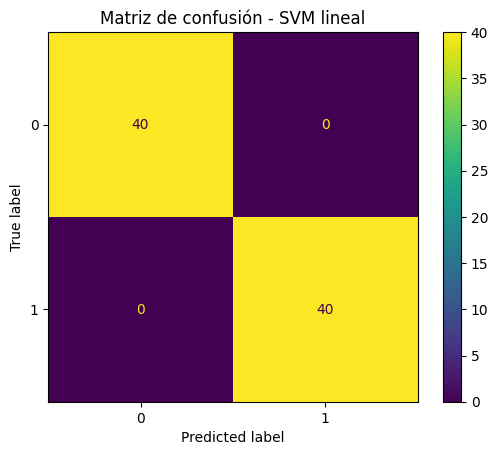

In [ ]:
predicciones = modelo.predict(X_test)
print(f"Exactitud de prueba: {accuracy_score(y_test, predicciones):.2%}")
print("Matriz de confusión:\n", confusion_matrix(y_test, predicciones))
print("\nReporte de clasificación:\n", classification_report(y_test, predicciones, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, predicciones)
plt.title("Matriz de confusión - SVM lineal")
plt.show()

## 12. Predecir puntos nuevos

Se aplica la misma recta aprendida a valores que no se introdujeron como ejemplos nuevos en el entrenamiento. El puntaje positivo corresponde a clase 1; el negativo, a clase 0.

In [ ]:
X_nuevos = np.array([[-2.0, -1.0], [1.0, 1.5], [0.0, 0.0], [2.0, 0.5]])
clases_nuevas = modelo.predict(X_nuevos)
puntajes = modelo.decision_function(X_nuevos)
for punto, clase, puntaje in zip(X_nuevos, clases_nuevas, puntajes):
    print(f"Punto {punto} -> clase {clase} | f(x) = {puntaje:.3f}")

Punto [-2. -1.] -> clase 0 | f(x) = -2.536
Punto [1.  1.5] -> clase 1 | f(x) = 2.764
Punto [0. 0.] -> clase 1 | f(x) = 0.392
Punto [2.  0.5] -> clase 1 | f(x) = 2.867


## 13. SVM vs. Perceptrón (comparación breve, opcional)

Los dos crean rectas. El Perceptrón busca una recta que clasifique; la SVM busca una que además favorezca un margen amplio. Para simplificar, solo comparamos exactitud y no hacemos un segundo experimento de kernels.

In [ ]:
from sklearn.linear_model import Perceptron
perceptron = Pipeline([("escalador", StandardScaler()),
                       ("modelo", Perceptron(random_state=SEED, max_iter=2000))])
perceptron.fit(X_train, y_train)
print(f"Perceptrón: {perceptron.score(X_test, y_test):.2%} de aciertos en prueba")
print(f"SVM lineal: {modelo.score(X_test, y_test):.2%} de aciertos en prueba")

Perceptrón: 100.00% de aciertos en prueba
SVM lineal: 100.00% de aciertos en prueba


## 14. Conclusiones y preguntas típicas del profesor

1. **¿Qué tipo de SVM usé?** Lineal: `SVC(kernel="linear", C=1.0)`.
2. **¿Por qué funciona una recta?** Porque este nuevo dataset se construyó con grupos linealmente separables.
3. **¿Qué son los vectores de soporte?** Puntos del entrenamiento cercanos al margen que influyen en la posición de la frontera.
4. **¿Qué hacen `w` y `b`?** Definen la recta $w_1x_1+w_2x_2+b=0$.
5. **¿Qué es `f_manual`?** La misma cuenta lineal escrita directamente con NumPy.
6. **¿Qué es `f_sklearn`?** El puntaje calculado por `decision_function()`.
7. **¿Usé kernel RBF?** **No.** Solo lo describí en la teoría para mostrar que existen otros métodos para problemas curvos.

**Nota:** el dataset es artificial y relativamente fácil. Un resultado alto en este tutorial no implica que SVM lineal siempre funcione bien en problemas reales.